In [ ]:
pip install torch torchvision matplotlib numpy scikit-learn captum

In [69]:
import sys
import os

sys.path.append(
    '/Users/zeynepoykuerdem/master_thesis/master_thesis'
)

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

print(f"PyTorch version: {torch.__version__}")
device = torch.device(
    "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
print(f"Using device: {device}")

PyTorch version: 2.10.0
Using device: mps


In [70]:
from data.cifar10_loader import load_cifar10_data,train_data_loader, test_data_loader

train_data,test_data=load_cifar10_data()
batch_size=64

#Loader
train_loader=train_data_loader(train_data,batch_size)
test_loader=test_data_loader(test_data,batch_size)

# Test
images, labels = next(iter(train_loader))
print(f"Batch shape: {images.shape}")
print(f"Labels shape: {labels.shape}")

/Users/zeynepoykuerdem/.pyenv/versions/thesis_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Batch shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])


In [71]:
from models.cnn_model import SimpleCNN
model = SimpleCNN(num_classes=10).to(device)

/Users/zeynepoykuerdem/.pyenv/versions/thesis_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch[10/50]Loss:0.6073Accuracy:79.47
Epoch[20/50]Loss:0.5844Accuracy:80.45
Epoch[30/50]Loss:0.5688Accuracy:80.76
Epoch[40/50]Loss:0.5648Accuracy:80.75
Epoch[50/50]Loss:0.5528Accuracy:81.41


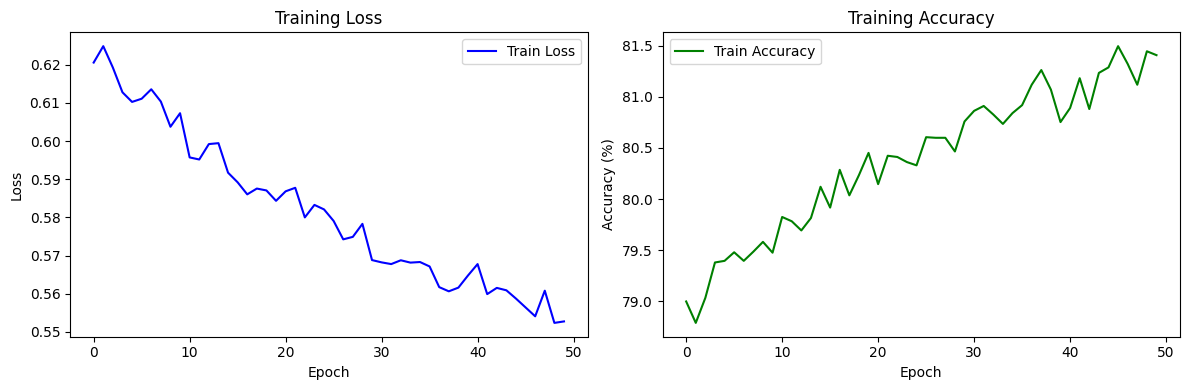

In [48]:

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torch.autograd import backward


loss_function=nn.CrossEntropyLoss()
optimizer= torch.optim.SGD(
    model.parameters(),
    lr=0.001,
    weight_decay=0.005,
    momentum=0.9)

history={
    'train_loss' :[],
    'train_acc':[]
}

num_epochs=50
for epoch in range (num_epochs):
    model.train()
    correct =0
    total =0
    epoch_loss =0
    for images,labels in train_loader:
        images=images.to(device)
        labels=labels.to(device)
        
        #forward pass
        outputs=model(images)
        loss= loss_function(outputs,labels)
        
        optimizer.zero_grad()# reset the gradients all optimized
        # backward pass and optimize
        loss.backward()
        optimizer.step()

        #Accuracy
        epoch_loss+= loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total   += labels.size(0)
        correct += (predicted == labels).sum().item()
        
    avg_loss= epoch_loss/ len(train_loader)
    accuracy = 100*correct/total
    history['train_acc'].append(accuracy)
    history['train_loss'].append(avg_loss)

    
    if(epoch + 1)%10==0:
        print(f"Epoch[{epoch+1}/{num_epochs}]"
              f"Loss:{avg_loss:.4f}"f"Accuracy:{accuracy:.2f}")
        
    
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss
ax1.plot(history['train_loss'], label='Train Loss', color='blue')
ax1.set_title('Training Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

# Accuracy
ax2.plot(history['train_acc'], label='Train Accuracy', color='green')
ax2.set_title('Training Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()

plt.tight_layout()
plt.savefig('/Users/zeynepoykuerdem/master_thesis/figures/training_history.png')
plt.show()


In [72]:
print(f"Device:{device}")
print(f"MPS Available : {torch.backends.mps.is_available()}")

Device:mps
MPS Available : True


Epoch_number= 20 →50
learning_rate=0.001 → 0.01

In [74]:
def train_experiment(exp_model, loader, num_epochs=50):
    exp_optimizer = torch.optim.SGD(
        exp_model.parameters(),
        lr=0.01,
        weight_decay=0.005,
        momentum=0.9
    )
    exp_loss_fn = nn.CrossEntropyLoss()

    history = {'loss': [], 'acc': []}

    for epoch in range(num_epochs):
        exp_model.train()
        correct    = 0
        total      = 0
        epoch_loss = 0.0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = exp_model(images)
            loss    = exp_loss_fn(outputs, labels)

            exp_optimizer.zero_grad()
            loss.backward()
            exp_optimizer.step()

            epoch_loss   += loss.item()
            _, predicted  = torch.max(outputs.data, 1)
            total        += labels.size(0)
            correct      += (predicted == labels).sum().item()

        avg_loss = epoch_loss / len(loader)
        accuracy = 100.0 * correct / total

        history['loss'].append(avg_loss)
        history['acc'].append(accuracy)

        if (epoch + 1) % 10 == 0:
            print(f"  Epoch [{epoch+1}/{num_epochs}]  "
                  f"Loss: {avg_loss:.4f}  "
                  f"Accuracy: {accuracy:.2f}%")

    return history

In [75]:
def evaluate_model(loader, loss_fn,model):
    eval_model=model.to(device)
    eval_model.eval()
    correct    = 0
    total      = 0
    epoch_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            y_pred = eval_model(images)
            loss   = loss_fn(y_pred, labels)

            epoch_loss   += loss.item()
            _, predicted  = torch.max(y_pred.data, 1)
            total        += labels.size(0)
            correct      += (predicted == labels).sum().item()

    avg_loss = epoch_loss / len(loader)
    accuracy = 100.0 * correct / total

    return accuracy, avg_loss








In [76]:
def plot_history(history, title='', save_path=None):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Loss — hangi key varsa onu kullan
    loss_key = 'train_loss' if 'train_loss' in history else 'loss'
    acc_key  = 'train_acc'  if 'train_acc'  in history else 'acc'

    # Loss plot
    if loss_key in history:
        ax1.plot(history[loss_key], label='Train Loss', color='blue')
    if 'test_loss' in history:
        ax1.plot(history['test_loss'], label='Test Loss', color='red')
    ax1.set_title(f'{title} Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()

    # Accuracy plot
    if acc_key in history:
        ax2.plot(history[acc_key], label='Train Accuracy', color='green')
    if 'test_acc' in history:
        ax2.plot(history['test_acc'], label='Test Accuracy', color='orange')
    ax2.set_title(f'{title} Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()

    plt.suptitle(title)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path)
        print(f"Saved: {save_path}")

    plt.show()
   

## Zhang et al. (2021) Experiment
Label Shuffling and Random Pixels — demonstrating memorization effect

"Most of our randomization tests are performed with
explicit regularization turned off"


In [78]:
from data.nosiy_data import ZhangExperiment
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from data.cifar10_loader import load_cifar10_data_no_augmentation

base_dataset=load_cifar10_data_no_augmentation()


true_dataset= ZhangExperiment(base_dataset,'true')

random_labels= ZhangExperiment(base_dataset,'random_labels')

random_pixels= ZhangExperiment(base_dataset,'random_pixels')



# Data Loaders
true_loader  = DataLoader(true_dataset,  batch_size=64)
label_loader = DataLoader(random_labels, batch_size=64)
pixel_loader = DataLoader(random_pixels, batch_size=64)


ImportError: cannot import name 'load_cifar10_data_no_augmentation' from 'data.cifar10_loader' (/Users/zeynepoykuerdem/master_thesis/master_thesis/data/cifar10_loader.py)

Train Model by each experiment's
Training Loss and Training Accuracy


Experiment: True Labels


/Users/zeynepoykuerdem/.pyenv/versions/thesis_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
  Epoch [10/20]  Loss: 0.8992  Accuracy: 68.42%
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
  Epoch [20/20]  Loss: 0.7412  Accuracy: 74.43%
Saved: /Users/zeynepoykuerdem/master_thesis/figures/true_labels_history.png


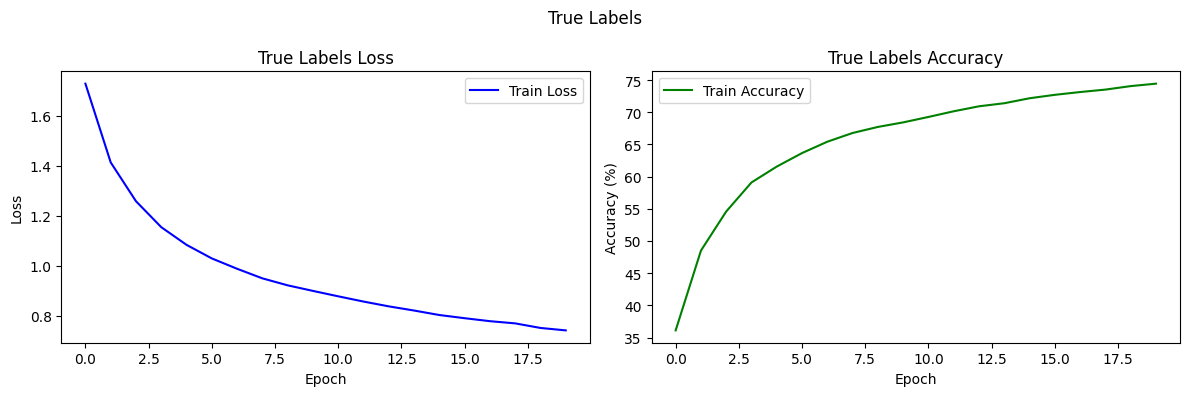

Test Accuracy: 77.62%  Test Loss: 0.6328

Experiment: Random Labels
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
  Epoch [10/20]  Loss: 2.3025  Accuracy: 10.39%
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
  Epoch [20/20]  Loss: 2.3022  Accuracy: 10.45%
Saved: /Users/zeynepoykuerdem/master_thesis/figures/random_labels_history.png


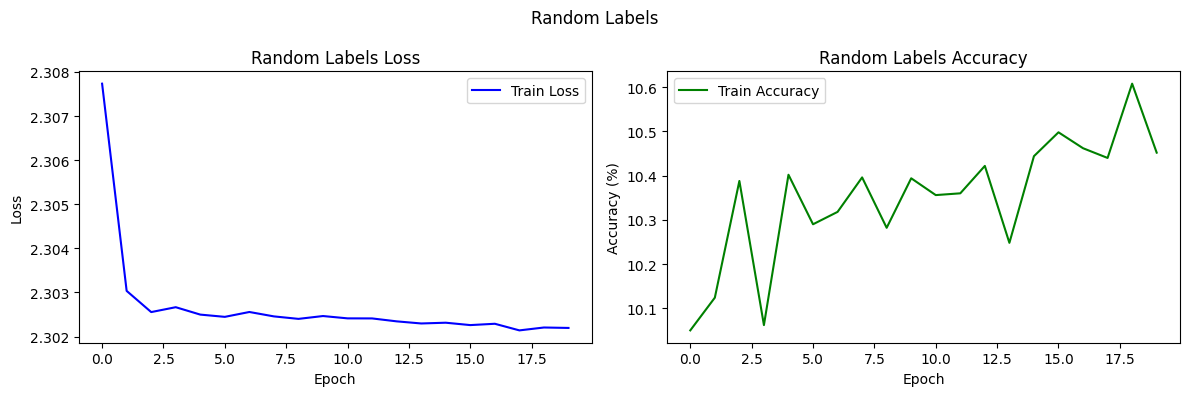

Test Accuracy: 7.03%  Test Loss: 2.3027

Experiment: Random Pixels
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
  Epoch [10/20]  Loss: 2.3027  Accuracy: 9.76%
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
Using device: mps
  Epoch [20/20]  Loss: 2.3026  Accuracy: 9.92%
Saved: /Users/zeynepoykuerdem/master_thesis/figures/random_pixels_history.png


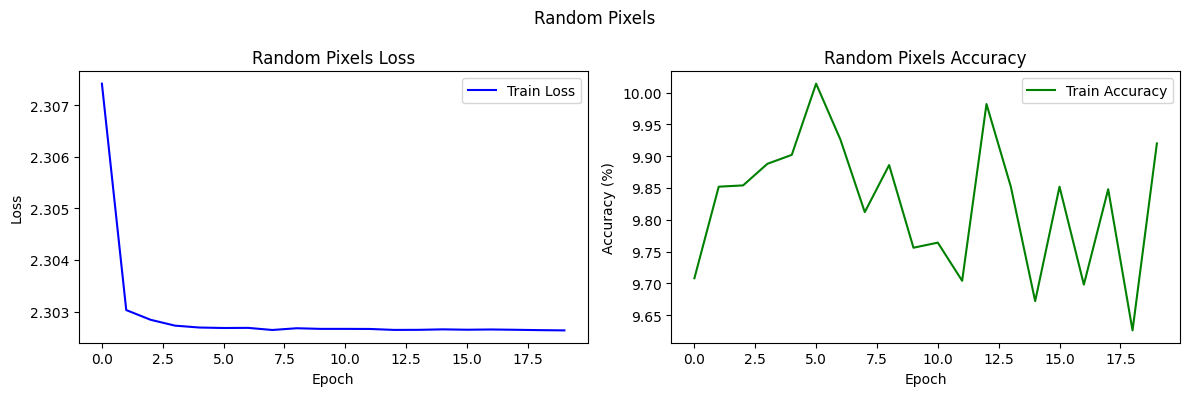

Test Accuracy: 10.76%  Test Loss: 2.3025


In [54]:
experiments = {
    'True Labels':    true_loader,
    'Random Labels':  label_loader,
    'Random Pixels':  pixel_loader
}
results={}
figures_dir = '/Users/zeynepoykuerdem/master_thesis/figures'


for exp_name,loader in experiments.items():
   print(f"\nExperiment: {exp_name}")
   exp_model=SimpleCNN(num_classes=10).to(device)
   
   history=train_experiment(exp_model,loader)
   #training loss and accuracy plotting
   safe_name = exp_name.replace(' ', '_').lower()
   plot_history(history,title=exp_name,save_path=f'{figures_dir}/{safe_name}_history.png')

   test_acc, test_loss = evaluate_model(test_loader, loss_function, exp_model)
   print(f"Test Accuracy: {test_acc:.2f}%  Test Loss: {test_loss:.4f}")
  
   
   results[exp_name] = {
        'train_accuracy': history['acc'][-1],
        'train_loss': history['loss'][-1],
        'test_accuracy': test_acc,
        'test_loss': test_loss
    }
   


   

   

     

     
        



            






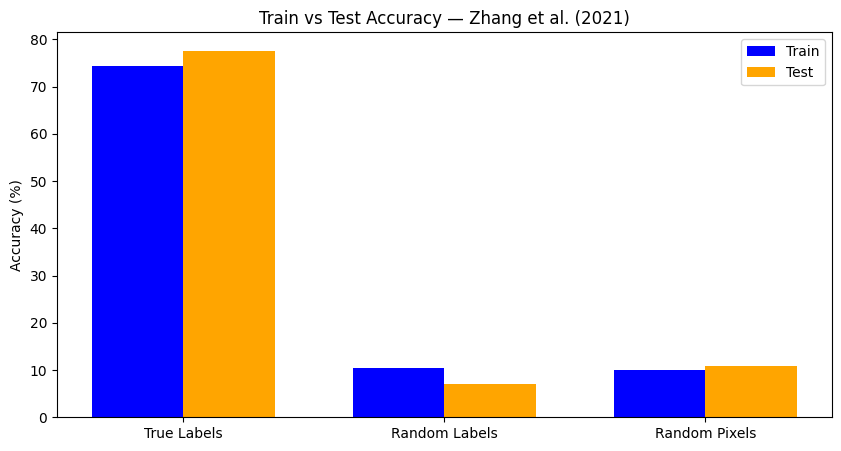

In [57]:
exp_names  = list(results.keys())
figures_dir = '/Users/zeynepoykuerdem/master_thesis/figures'

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(exp_names))
w = 0.35

ax.bar(x - w/2, [results[e]['train_accuracy'] for e in exp_names], w, label='Train', color='blue')
ax.bar(x + w/2, [results[e]['test_accuracy']  for e in exp_names], w, label='Test',  color='orange')
ax.set_xticks(x)
ax.set_xticklabels(exp_names)
ax.set_title('Train vs Test Accuracy — Zhang et al. (2021)')
ax.set_ylabel('Accuracy (%)')
ax.legend()
plt.savefig(f'{figures_dir}/zhang_comparison.png')
plt.show()


## Predicted Class

## Grad-Cam Implementation

1- Determine the target layer
2- Compute the most probable class
3- Gradient of the most probable class
4- Pool the gradients
5- Weight Channels by corresponding pool gradients
6- Heatmap

In [ ]:
!pip install grad-cam

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
the_target_layer= model.block3[0] # the las conv layer of the model

grad_cam= GradCAM( model=model, target_layers=[the_target_layer],use_mps=device.type=='mps')

#test_batch
test_images,test_labels= next(iter(test_loader))
test_images=test_images.to(device)
test_labels=test_labels.to(device)

input_tensor = test_images[0].unsqueeze(0).to(device)#single image
targets = [ClassifierOutputTarget(label.item()) for label in test_labels]

grayscale_cam= grad_cam(input_tensor=input_tensor,targets=targets)

# Conver the input image from normalized tensor to image format
mean     = np.array([0.4914, 0.4822, 0.4465])
std      = np.array([0.2023, 0.1994, 0.2010])

image_show=test_images[0].cpu().numpy().transpose(1,2,0) * std + mean

image_show = np.clip(image_show, 0, 1).astype(np.float32)


visualization = show_cam_on_image(image_show, grayscale_cam[0], use_rgb=True)
plt.imshow(visualization)
plt.show()






